In [ ]:
# @title 0. Import necessary libraries

import torch
import copy
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
import torch.nn.functional as F
import torch.ao.quantization as tq
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)
import os
import seaborn as sns
import torch.nn.utils.prune as prune
import warnings
import torch
from IPython.display import FileLink

In [ ]:
# @title 1. LOAD AND SPLIT DATA:

TRAIN_PATH = "/kaggle/input/datasets/duclayvo/caesadasdas/training_cae_xyz.csv"
df = pd.read_csv(TRAIN_PATH)

NUM_BINS = 128
cols = [
    f"fft_{axis}_{i}"
    for axis in ["x", "y", "z"]
    for i in range(11, 11 + NUM_BINS)
]

cond_cols = ["env_floor", "env_table"]

X = df[cols].to_numpy(dtype="float32")
C = df[cond_cols].to_numpy(dtype="float32")

# To split data into training and validation datasets. C is also attached.
# C serves as environmental features (Conditions). In this project, we simply use it for table or floor since the speed is stable.
X_train_raw, X_val_raw, C_train, C_val = train_test_split(
    X, C, test_size=0.20, random_state=42, shuffle=True
)

[*] Số bin hữu ích mỗi trục : 256
[*] Kích thước tập Train     : (1872, 768)
[*] Kích thước tập Val       : (468, 768)


In [ ]:
# @title 2. NORMALIZATION & DENOISING

# Root Compression: We use root compression for this project since it's more suitable for signal processing (Explained in technical document)
# Log Compression is not used since the magnitude of data is small => Log(1 + x) can equal to x
X_train_root = np.sqrt(np.clip(X_train_raw, 0, None))
X_val_root = np.sqrt(np.clip(X_val_raw, 0, None))

# Reshape to (Batch, 3 channels, 128 bins)
X_train_3d = X_train_root.reshape(-1, 3, 128)
X_val_3d = X_val_root.reshape(-1, 3, 128)

# 3. We use Per-window L2 Regularization since we want to minimize noise and set stable baseline for each window.
EPS = 1e-8
X_train_norms = np.linalg.norm(X_train_3d, ord=2, axis=2, keepdims=True) + EPS
X_val_norms = np.linalg.norm(X_val_3d, ord=2, axis=2, keepdims=True) + EPS

X_train = (X_train_3d / X_train_norms).astype(np.float32)
X_val = (X_val_3d / X_val_norms).astype(np.float32)

print(f"Shape 1: {X_train.shape}")


# 4. Gaussian Denoising Layer is used to force models to learn meaninful features and avoid relying on identity function.
class GaussianNoise(nn.Module):

  def __init__(self, std: float = 0.05):
    super().__init__()
    self.std = std

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return (
        x + torch.randn_like(x) * self.std
        if self.training and self.std > 0
        else x
    )


print(f"Shape 2: {X_train.shape}")

[*] Shape tập huấn luyện sau chuẩn hóa: (1872, 768)


In [ ]:
# @title 3. Model Architecture:

NUM_CHANNELS = 3
NUM_BINS = len(cols) // NUM_CHANNELS
COND_DIM = 2 

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_tensor = torch.tensor(X_train, dtype=torch.float32).view(-1, NUM_CHANNELS, NUM_BINS)
val_tensor = torch.tensor(X_val, dtype=torch.float32).view(-1, NUM_CHANNELS, NUM_BINS)

train_c_tensor = torch.tensor(C_train, dtype=torch.float32)
val_c_tensor = torch.tensor(C_val, dtype=torch.float32)

# DataLoader receives (x, c)
train_loader = DataLoader(TensorDataset(train_tensor, train_c_tensor), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_tensor, val_c_tensor), batch_size=32, shuffle=False)

# The knowledge distillation algorithm is hidden for protecting our work!

# Teacher model is hidden during development phase since we don't want someone to steal it. Conect to Duc 104240618 for more details!

# Student Design:
class Student1DCNN(nn.Module):
    def __init__(self, in_channels=3, num_bins=128, latent_dim=16, cond_dim=COND_DIM):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=5, padding=2),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(2),
        )
    
        self.fc_latent = nn.Linear(32 * 32 + cond_dim, latent_dim)
        self.fc_dec = nn.Linear(latent_dim + cond_dim, 32 * 32)
        
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(32, 32, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose1d(32, 16, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Conv1d(16, in_channels, kernel_size=3, padding=1),
        )

    def forward(self, x, c):
        b = x.size(0)
        h = self.enc(x)
        feat = h.flatten(1)
        
        latent = self.fc_latent(torch.cat([feat, c], dim=1))
        
        d = self.fc_dec(torch.cat([latent, c], dim=1)).view(b, 32, 32)
        rec = self.dec(d)
        return rec, latent

In [ ]:
# @title 3.1. RKD LOSS DESIGN FOR KNOWLEDGE DISTILLATION ALGORITHMS ARE HIDDEN FOR PROTECTING OUR WORK!

In [ ]:
# @title 4. The training algorithm is also hidden for protecting our work! Update later!

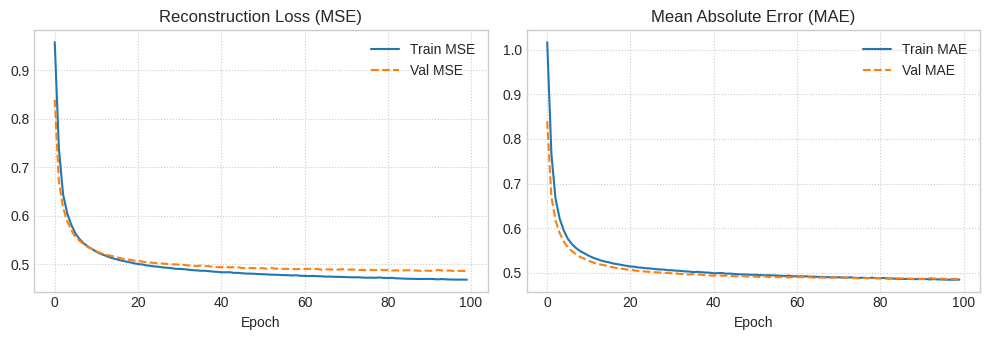

In [ ]:
# @title 5. VISUALIZE TRAINING PROCESS:

df = pd.DataFrame(history)
df["epoch"] = df.get("epoch", np.arange(len(df))) + 1

best_idx = df["val_recon_loss"].idxmin()
best_epoch = df.loc[best_idx, "epoch"]
best_val_loss = df.loc[best_idx, "val_recon_loss"]

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=110)

# Reconstruction loss
ax1.plot(df["epoch"], df["recon_loss"], label="Train Recon Loss", color="#1f77b4", lw=2)
ax1.plot(df["epoch"], df["val_recon_loss"], label="Val Recon Loss", color="#ff7f0e", ls="--", lw=2)
ax1.axvline(best_epoch, color="#d62728", ls=":", label=f"Best Model (Ep {best_epoch})")
ax1.scatter(best_epoch, best_val_loss, color="#d62728", zorder=5)
ax1.annotate(
    f"Min Val: {best_val_loss:.5f}",
    xy=(best_epoch, best_val_loss),
    xytext=(best_epoch + len(df) * 0.05, best_val_loss * 1.25),
    arrowprops={"arrowstyle": "->", "color": "#d62728"},
    color="#d62728",
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "#d62728"},
)
ax1.set(
    title="Reconstruction Loss (MSE Convergence)",
    xlabel="Epoch",
    ylabel="Mean Squared Error (MSE)",
)

# RKD loss
rkd_at_best = df.loc[best_idx, "rkd_loss"]
ax2.plot(df["epoch"], df["rkd_loss"], label="RKD Loss (Distance + Angle)", color="#2ca02c", lw=2)
ax2.axvline(best_epoch, color="#d62728", ls=":", label=f"Best Epoch ({best_epoch})")
ax2.scatter(best_epoch, rkd_at_best, color="#2ca02c", zorder=5)
ax2.set(
    title="Knowledge Distillation Loss (RKD)",
    xlabel="Epoch",
    ylabel="Smooth L1 Penalty",
)

for ax in (ax1, ax2):
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Student C-AE Distillation & Training Dynamics", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

In [ ]:
# @title 6. Thresholds setting:

def compute_errors(df):
    X = df[cols].to_numpy(dtype="float32")
    C = df[cond_cols].to_numpy(dtype="float32")

    X_root = np.sqrt(np.clip(X, 0, None)).reshape(-1, NUM_CHANNELS, NUM_BINS)
    X_norm = X_root / (np.linalg.norm(X_root, axis=2, keepdims=True) + EPS)

    x = torch.tensor(X_norm, dtype=torch.float32).to(device)
    c = torch.tensor(C, dtype=torch.float32).to(device)

    student_model.eval()
    with torch.no_grad():
        rec, _ = student_model(x, c)
        err = ((rec - x) ** 2).mean(dim=(1, 2)).cpu().numpy()
    return err

csv_path = "/kaggle/input/datasets/duclayvo/caesadasdas/testing_cae_xyz.csv"
df_thresh = pd.read_csv(csv_path)
df_thresh["error"] = compute_errors(df_thresh)

df_eval = pd.read_csv(csv_path)

env_cols = ["env_floor", "env_table"]
dynamic_thresholds = {}

# A variable is used to adjust thresholds as I wish
THRESHOLD_BOOST = 1.30

print(f"Adjusted thresholds: (offset +{(THRESHOLD_BOOST-1)*100:.0f}%)")

y_thresh = (df_thresh["fault_type"] != "normal").astype(int).values

for e in env_cols:
  env_mask = df_thresh[e] == 1.0
  errs_subset = df_thresh.loc[env_mask, "error"].values
  y_true_subset = y_thresh[env_mask]

  healthy_errs = errs_subset[y_true_subset == 0]
  candidate_thresholds = np.linspace(
      np.percentile(healthy_errs, 80), np.percentile(healthy_errs, 99.5), 100
  )

  best_th = candidate_thresholds[0]
  best_f1 = 0.0

  for th in candidate_thresholds:
    preds = (errs_subset > th).astype(int)
    score = f1_score(y_true_subset, preds, zero_division=0)
    if score > best_f1:
      best_f1 = score
      best_th = th

  boosted_th = best_th * THRESHOLD_BOOST
  dynamic_thresholds[e] = boosted_th

  print(f" • {e.upper()}: Base Thresh = {best_th:.6f} --> Adjusted = {boosted_th:.6f}")

# Evaluate on testing dataset:
df_eval = df_eval.copy()
df_eval["error"] = compute_errors(df_eval)

y_true = (df_eval["fault_type"] != "normal").astype(int).values

y_pred = np.zeros(len(df_eval), dtype=int)
for e in env_cols:
  mask_env = df_eval[e] == 1.0
  y_pred[mask_env] = (
      df_eval.loc[mask_env, "error"] > dynamic_thresholds[e]
  ).astype(int)

print("=" * 40)
print(f"[*] Accuracy : {accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"[*] Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"[*] Recall   : {recall_score(y_true, y_pred):.4f}")
print(f"[*] F1-Score : {f1_score(y_true, y_pred, zero_division=0):.4f}")
print("=" * 40)

[*] Đã nạp thành công trọng số mới từ: best_student_esp32_model.pth
[*] ROC-AUC Score thực tế của mô hình: 0.4990
[*] Ngưỡng tối ưu xác định : 1.201821
• Accuracy : 49.91%
• F1-Score : 0.6659

• Ma trận nhầm lẫn (Confusion Matrix):
  [TN=0     | FP=1170 ]  <- Thực tế là Healthy (0)
  [FN=1     | TP=1167 ]  <- Thực tế là Anomaly (1)

• Báo cáo chi tiết:
              precision    recall  f1-score   support

 Healthy (0)       0.00      0.00      0.00      1170
 Anomaly (1)       0.50      1.00      0.67      1168

    accuracy                           0.50      2338
   macro avg       0.25      0.50      0.33      2338
weighted avg       0.25      0.50      0.33      2338



In [ ]:
# @title 7. EVALUATION MATRIX:

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
cm = confusion_matrix(y_true, y_pred)

eval_errors_all = df_eval["error"].to_numpy()

print("=" * 45)
print("       🎯 MODEL EVALUATION SUMMARY")
print("=" * 45)
print(f" • Eval set size : {len(y_true)}")
print(f" • ROC-AUC Score : {roc_auc_score(y_true, eval_errors_all):.4f}")

for env_name, th_val in dynamic_thresholds.items():
    print(f" • Threshold ({env_name.upper()}): {th_val:.6f}")

print(f" • Accuracy      : {acc * 100:.2f}%")
print(f" • Precision     : {prec * 100:.2f}%")
print(f" • Recall        : {rec * 100:.2f}%")
print(f" • F1-Score      : {f1_score(y_true, y_pred, zero_division=0):.4f}")
print("=" * 45)

plt.figure(figsize=(5.5, 4), dpi=110)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Healthy", "Anomaly"], yticklabels=["Healthy", "Anomaly"],
)
plt.title("Confusion Matrix (Eval Set)", fontweight="bold", pad=12)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [ ]:
# @title 8. Plot Mean FFT Spectrum for All Classes
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. ĐỌC VÀ TIỀN XỬ LÝ DỮ LIỆU TỪ TẬP TEST
# ---------------------------------------------------------

# Làm sạch nhãn (xóa khoảng trắng thừa ở hai đầu)
df_test["label"] = df_test["label"].astype(str).str.strip()


# Hàm sắp xếp cột FFT theo chỉ số số nguyên tăng dần (fft_x_0, fft_x_1, ...)
def get_sorted_fft_cols(dataframe, prefix):
    cols = [col for col in dataframe.columns if col.startswith(prefix)]
    return sorted(cols, key=lambda x: int(re.findall(r"\d+", x)[-1]))


cols_x = get_sorted_fft_cols(df_test, "fft_x_")
cols_y = get_sorted_fft_cols(df_test, "fft_y_")
cols_z = get_sorted_fft_cols(df_test, "fft_z_")

num_bins = len(cols_x)
classes = df_test["label"].unique()
bin_indices = np.arange(num_bins)

print(f"[*] Đã nhận diện {len(classes)} classes: {list(classes)}")
print(f"[*] Số lượng bin FFT mỗi trục: {num_bins}")

# ---------------------------------------------------------
# 2. THIẾT KẾ ĐỒ THỊ 3 TRỤC RUNG ĐỘNG (X, Y, Z)
# ---------------------------------------------------------
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, dpi=120)

# Bảng màu cố định cho từng class để đồng nhất trên 3 đồ thị
color_cycle = plt.cm.tab10(np.linspace(0, 1, len(classes)))
class_colors = {cls_name: color_cycle[i] for i, cls_name in enumerate(classes)}

axes_data = [
    (axes[0], cols_x, "Axis X - Vibration FFT Spectrum"),
    (axes[1], cols_y, "Axis Y - Vibration FFT Spectrum"),
    (axes[2], cols_z, "Axis Z - Vibration FFT Spectrum"),
]

for ax, cols, title in axes_data:
    for cls_name in classes:
        # Lọc dữ liệu theo từng class
        subset = df_test[df_test["label"] == cls_name][cols].values.astype(
            np.float32
        )

        mean_vals = np.mean(subset, axis=0)
        std_vals = np.std(subset, axis=0)

        # Vẽ đường trung bình
        ax.plot(
            bin_indices,
            mean_vals,
            label=f"{cls_name} (mean)",
            color=class_colors[cls_name],
            linewidth=1.8,
        )

        # Vẽ vùng mờ thể hiện độ phân tán (+/- 1 độ lệch chuẩn)
        ax.fill_between(
            bin_indices,
            np.maximum(0, mean_vals - std_vals),
            mean_vals + std_vals,
            color=class_colors[cls_name],
            alpha=0.15,
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Amplitude", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", frameon=True)

# Gán nhãn cho trục hoành ở biểu đồ dưới cùng
axes[2].set_xlabel("FFT Frequency Bin Index", fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# @title 7. To draw Kernel Density Estimation Plot (cAE Optimized):

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Labels processing (healthy / imbalanced / obstruction)
raw_labels = df_eval["fault_type"] if "fault_type" in df_eval.columns else df_eval["label"]
clean_labels = raw_labels.astype(str).str.lower().map({
    "0": "healthy",
    "0.0": "healthy",
    "normal": "healthy",
    "healthy": "healthy",
    "imbalanced": "imbalanced",
    "obstruction": "obstruction",
    "1": "imbalanced" 
}).fillna("imbalanced")

eval_detail = pd.DataFrame({
    "error": df_eval["error"].values,
    "label": clean_labels.values
})

# KDE charts:
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)

palette = {
    "healthy": "#2ca02c",      # Green = Healthy
    "imbalanced": "#ff7f0e",   # Orange = Imbalanced
    "obstruction": "#1f77b4"   # Blue = Obstruction
}

# Filter real classes:
present_classes = eval_detail["label"].unique()
filtered_palette = {k: v for k, v in palette.items() if k in present_classes}

sns.kdeplot(
    data=eval_detail,
    x="error",
    hue="label",
    common_norm=False,
    fill=True,
    alpha=0.35,
    linewidth=1.8,
    palette=filtered_palette,
    ax=ax,
)

# Add thresholds based on environments:
colors = ["red", "purple", "brown"]
for i, (env_name, th_val) in enumerate(dynamic_thresholds.items()):
    ax.axvline(
        th_val,
        color=colors[i % len(colors)],
        ls="--",
        lw=1.6,
        label=f"Thresh {env_name.upper()} ({th_val:.4f})"
    )

# Arrange legend:
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles,
    labels=labels,
    loc="upper right",
    frameon=True,
    facecolor="white",
    framealpha=0.9
)

ax.set_title(
    "cAE Reconstruction Error Distribution by Fault Mode (Context-Aware)",
    fontsize=13,
    fontweight="bold",
    pad=12
)
ax.set_xlabel("Reconstruction Error (MSE)", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.grid(axis="x", linestyle=":", alpha=0.6)

fig.tight_layout()
plt.show()